# 06 – Kvadratická časově-frekvenční distribuce: Smoothed Pseudo Wigner-Ville (SPWVD)
Výpočet kvadratické distribuce energie nad analytickým signálem s Gaussovým vyhlazovacím oknem pro potlačení křížových interferenčních členů a Rényiho entropií koncentrace.

Metriky separability (SPWVD): {'method_name': 'wvd', 'fdr_score': 0.1717, 'silhouette_score': -0.1084, 'davies_bouldin_score': 25.3791, 'mutual_info_mean': 0.2881, 'anova_f_mean': 210.5771, 'separability_by_phenomenon': {'static_load_fdr': 0.0835, 'thermal_fdr': 0.1762, 'transition_edge_fdr': 0.0026}}


,measurement_code,inherited_label,wvd_max_energy,wvd_peak_to_mean_ratio,wvd_renyi_concentration
0,0773,klid_pred_teplotou,5.083438e-07,5.180180,10.224966
1,0773,klid_pred_teplotou,5.854567e-07,4.898959,10.314141
2,0773,klid_pred_teplotou,7.526754e-07,5.047044,10.332434
3,0773,klid_pred_teplotou,1.822833e-06,6.814919,10.233012
4,0773,klid_pred_teplotou,2.129521e-06,6.778540,10.004358
5,0773,klid_pred_teplotou,1.238629e-06,5.507529,10.207478
6,0773,klid_pred_teplotou,1.016998e-06,6.159595,10.232563
7,0773,klid_pred_teplotou,1.497453e-06,6.399304,10.120890
8,0773,klid_pred_teplotou,1.588903e-06,6.723330,10.216855
9,0773,klid_pred_teplotou,1.795464e-06,6.383044,10.266747


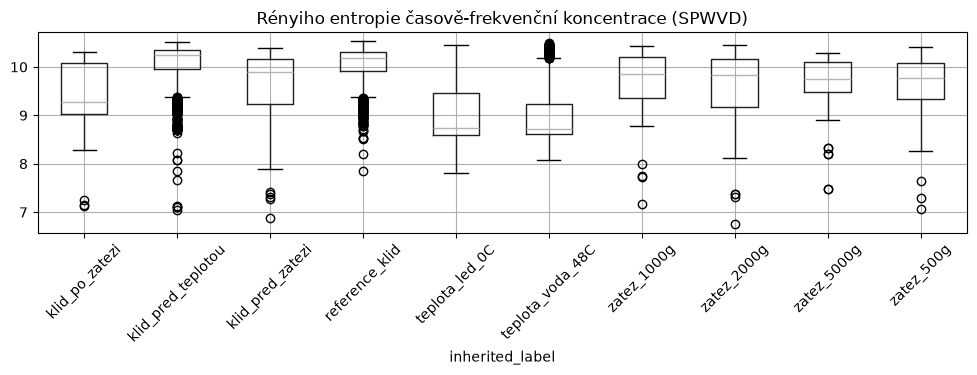

In [1]:
import matplotlib.pyplot as plt
from icaros.analysis.runner import load_windows_with_signals, run_single_silver_method
from icaros.db.s3 import read_parquet_from_s3

df_win, signals, fs = load_windows_with_signals("win128_stride32")
res = run_single_silver_method("wvd", df_win, signals, fs, "win128_stride32")
print("Metriky separability (SPWVD):", {k: v for k, v in res.items() if k != "s3_uri"})
df_wvd = read_parquet_from_s3(res["s3_uri"])
display(df_wvd[["measurement_code", "inherited_label", "wvd_max_energy", "wvd_peak_to_mean_ratio", "wvd_renyi_concentration"]].head(12))

fig, ax = plt.subplots(figsize=(10, 4))
df_wvd.boxplot(column="wvd_renyi_concentration", by="inherited_label", ax=ax, rot=45)
ax.set_title("Rényiho entropie časově-frekvenční koncentrace (SPWVD)")
plt.suptitle("")
plt.tight_layout()
plt.show()